# 1. Greedy Search vs. Beam Search

## First, why do we need them?

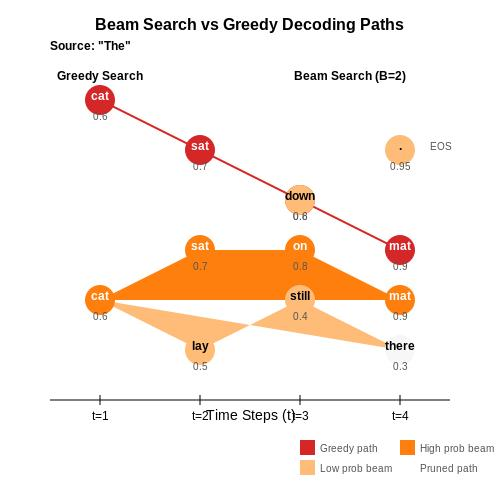

Imagine we're building a Seq2Seq machine translation model that translates:

Input: `Je suis heureux`

The decoder needs to generate an English translation one token at a time.

```
Decoder
   ↓
Predict first token
   ↓
Predict next token
   ↓
Predict next token
   ↓
Complete translation
```

At each step, the model assigns probabilities to possible next tokens. Greedy search and beam search are two strategies for choosing those tokens.

## A. Greedy search

Greedy search selects the token with the highest probability at the current step.

Suppose the decoder gives these probabilities:

Step 1 — Choose the first token

"I"

70%

"We"

20%

"They"

10%

Greedy chooses "I" because 70% is the highest probability.

Next, it chooses the highest-probability token after `"I"`, then the highest after that token, and so on.

The important limitation is that greedy search commits to each choice immediately. It doesn't keep alternative sentences in case an early choice leads to a worse overall result.

## B. Beam search

Beam search keeps multiple promising sentence candidates instead of committing to only one.

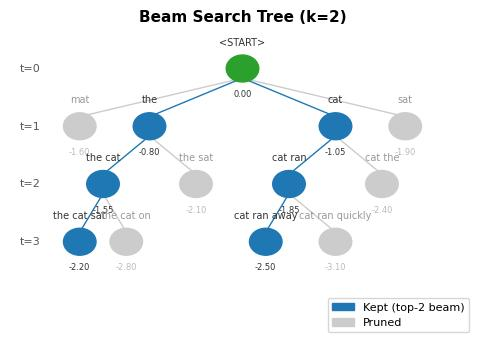

Let's use a simple example. Suppose the decoder has these candidate sequences:

Step 1 — Keep the top 2 choices

"I"

## 70%

"We"

## 20%

Beam width = 2, so both candidates are retained.

Step 2 — Expand both candidates

"I am"

Combined sequence score: 0.70 × 0.30 = 0.21

"We are"

Combined sequence score: 0.20 × 0.90 = 0.18

Illustrative probabilities only. Real models calculate conditional probabilities at each step.

Beam search continues expanding the retained candidates, comparing their cumulative scores and keeping the best ones at each step.

Unlike greedy search, it can preserve a less likely first token that eventually leads to a better-scoring complete sequence.

## C. The difference to remember

|             | Greedy search                      | Beam search                       |
| ----------- | ---------------------------------- | --------------------------------- |
| Keeps       | One candidate                      | Multiple candidates               |
| Decision    | Best next token                    | Best candidates by sequence score |
| Computation | Lower                              | Higher                            |
| Main risk   | Early choices can limit the result | Can still miss the best sequence  |

One detail: beam search is not guaranteed to find the globally best sentence. It only explores candidates that survive its limited beam.

---